In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nelgiriyewithana/top-spotify-songs-2023")

print("Path to dataset files:", path)

Path to dataset files: /home/codespace/.cache/kagglehub/datasets/nelgiriyewithana/top-spotify-songs-2023/versions/1


In [57]:
df = pd.read_csv(f'{path}/spotify-2023.csv', encoding='latin-1')
#df = pd.read_csv('data/spotify-2023.csv', encoding='latin-1')

df.shape
df.head()

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,...,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,...,144,A,Minor,65,23,80,14,63,11,6


In [4]:
df.columns = (
    df.columns.str.lower()
    .str.replace('_%', '', regex=False)
    .str.replace('(s)', '', regex=False)
)

df.columns.tolist()

['track_name',
 'artist_name',
 'artist_count',
 'released_year',
 'released_month',
 'released_day',
 'in_spotify_playlists',
 'in_spotify_charts',
 'streams',
 'in_apple_playlists',
 'in_apple_charts',
 'in_deezer_playlists',
 'in_deezer_charts',
 'in_shazam_charts',
 'bpm',
 'key',
 'mode',
 'danceability',
 'valence',
 'energy',
 'acousticness',
 'instrumentalness',
 'liveness',
 'speechiness']

In [5]:
df['streams'] = pd.to_numeric(df['streams'], errors='coerce')
df = df.dropna(subset=['streams']).reset_index(drop=True)
df['streams'] = df['streams'].astype(int)

df['key'] = df['key'].fillna('Unknown')

df = df.drop_duplicates(subset=['track_name', 'artist_name']).reset_index(drop=True)

In [6]:
streams_all = df['streams'].copy() # might not use this

threshold = df['streams'].quantile(0.75)
df['mega_hit'] = (df['streams'] >= threshold).astype(int)

In [7]:
audio = ['bpm', 'danceability', 'valence', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'speechiness']
numerical = audio + ['artist_count', 'released_year', 'released_day']
categorical = ['key', 'mode', 'released_month']

df = df[['track_name', 'artist_name'] + numerical + categorical + ['mega_hit']]
df.shape

(948, 17)

## Train/Test/Val Split

In [8]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['mega_hit'].values
y_val = df_val['mega_hit'].values
y_test = df_test['mega_hit'].values

del df_train['mega_hit']
del df_val['mega_hit']
del df_test['mega_hit']

len(df_train), len(df_val), len(df_test), y_train.mean(), y_val.mean(), y_test.mean()

(568,
 190,
 190,
 np.float64(0.25704225352112675),
 np.float64(0.22105263157894736),
 np.float64(0.2578947368421053))

# EDA

In [9]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.shape

(758, 17)

In [10]:
df_full_train[numerical].describe().round(1)

,bpm,danceability,valence,energy,acousticness,instrumentalness,liveness,speechiness,artist_count,released_year,released_day
count,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0
mean,122.0,67.0,51.9,64.5,26.7,1.5,18.0,10.1,1.6,2018.2,13.9
std,27.7,14.8,23.8,16.8,25.8,8.2,13.2,10.0,0.9,11.1,9.1
min,65.0,23.0,4.0,14.0,0.0,0.0,3.0,2.0,1.0,1930.0,1.0
25%,100.0,57.0,32.2,53.2,5.0,0.0,10.0,4.0,1.0,2020.0,6.0
50%,120.0,70.0,52.0,66.0,18.0,0.0,12.0,6.0,1.0,2022.0,13.0
75%,140.0,79.0,71.0,77.8,41.0,0.0,23.0,11.0,2.0,2022.0,21.0
max,206.0,96.0,97.0,97.0,97.0,90.0,92.0,64.0,7.0,2023.0,31.0


In [11]:
df_full_train[categorical].nunique()

key               12
mode               2
released_month    12
dtype: int64

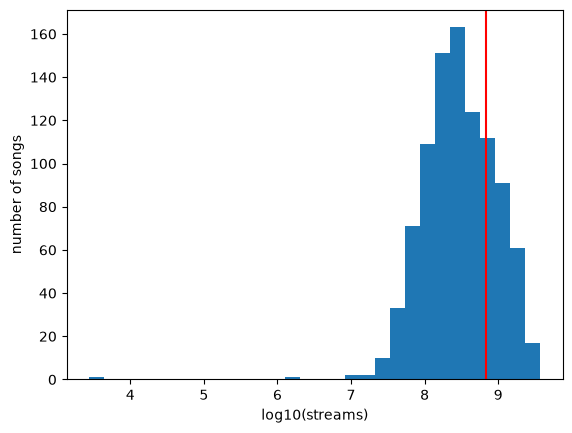

np.float64(0.24802110817941952)

In [12]:
global_rate = df_full_train['mega_hit'].mean()

plt.hist(np.log10(streams_all), bins=30)
plt.axvline(np.log10(threshold), color='red')
plt.xlabel('log10(streams)')
plt.ylabel('number of songs')
plt.show()
global_rate

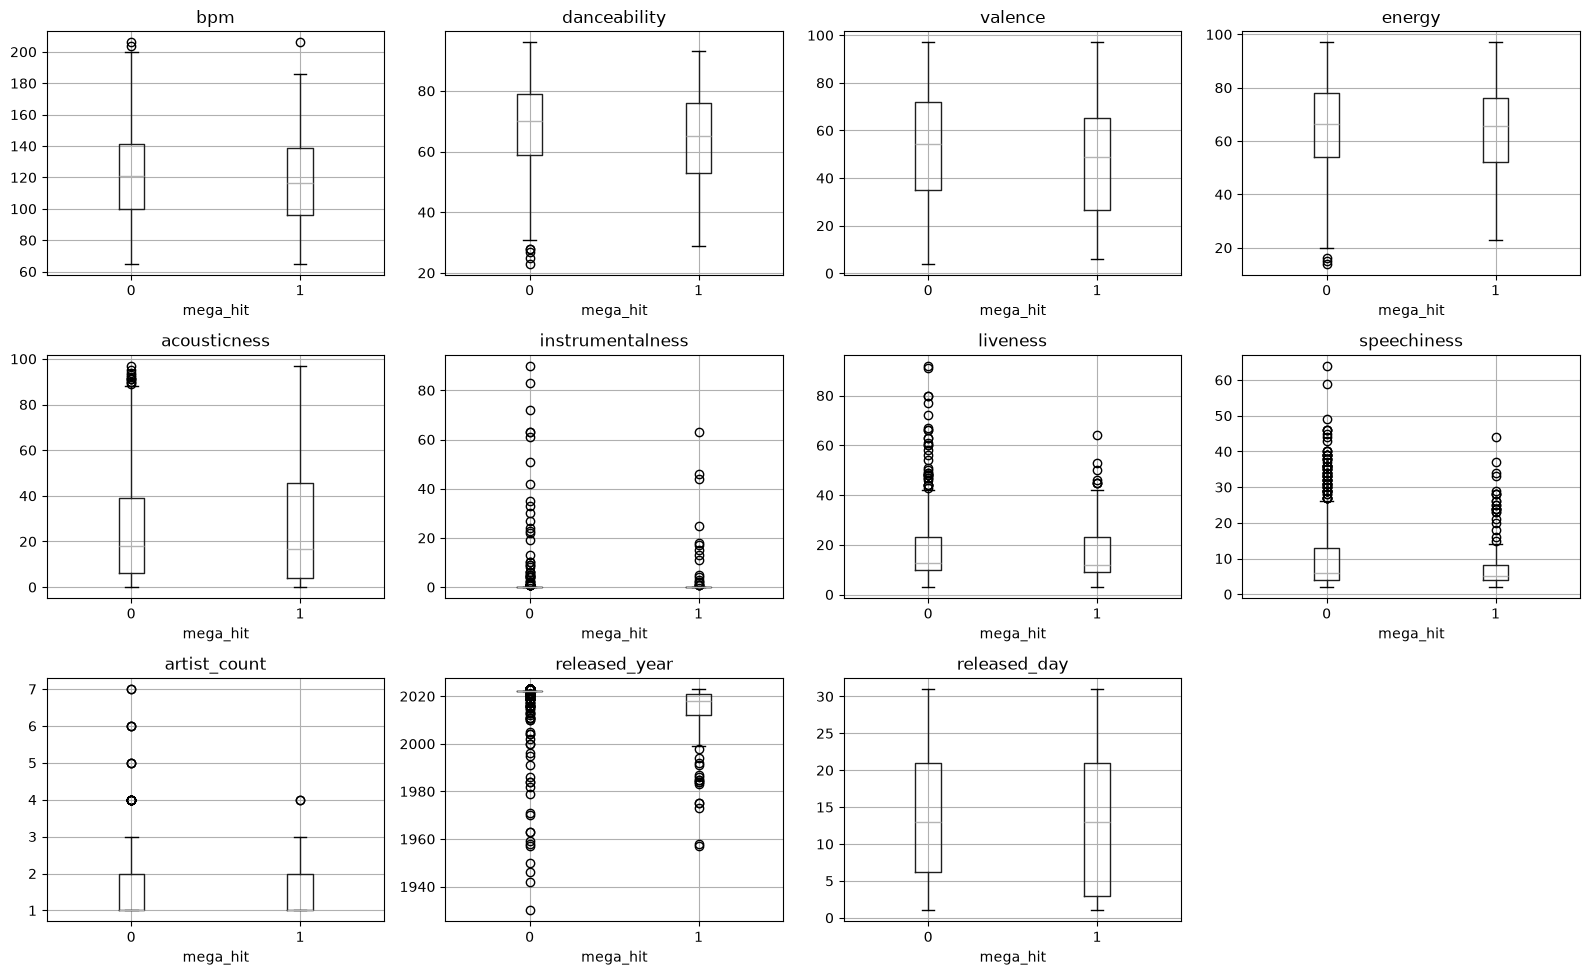

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), numerical):
    df_full_train.boxplot(column=col, by='mega_hit', ax=ax)
    ax.set_title(col)
for ax in axes.flatten()[len(numerical):]:
    ax.axis('off')
plt.suptitle('')
plt.tight_layout()
plt.show()

- For most audio features (bpm, energy, acousticness, liveness, instrumentalness) the boxes basically overlap, so the music alone doesn't separate the classes well.
- Speechiness and valence sit a little lower for mega-hits, which matches the small negative correlations from before.
- `released_year` is the one that looks different: mega-hits are spread across older years, while non-hits are bunched around 2020-2022 with a long tail of older outliers.
- `artist_count` has the same median (1) in both groups, but the non-hits include more songs with lots of artists.
- `released_day` looks identical in both groups, so it's probably safe to drop later.

In [14]:
from scipy.stats import pointbiserialr
from sklearn.metrics import roc_auc_score

rows = []
for col in numerical:
    corr, p = pointbiserialr(df_full_train['mega_hit'], df_full_train[col])
    auc = roc_auc_score(df_full_train['mega_hit'], df_full_train[col])
    rows.append({'feature': col, 'correlation': corr, 'p_value': p, 'auc': auc, 'auc_distance': abs(auc - 0.5)})

summary = pd.DataFrame(rows).set_index('feature').sort_values('auc_distance', ascending=False)
summary.round(3)

,correlation,p_value,auc,auc_distance
feature,,,,
released_year,-0.237,0.000,0.156,0.344
artist_count,-0.145,0.000,0.415,0.085
speechiness,-0.125,0.001,0.416,0.084
danceability,-0.115,0.002,0.426,0.074
valence,-0.095,0.009,0.437,0.063
bpm,-0.048,0.189,0.461,0.039
energy,-0.044,0.231,0.471,0.029
liveness,-0.042,0.248,0.471,0.029
released_day,-0.021,0.563,0.474,0.026


- `released_year` is by far the strongest. Older songs are way more likely to be mega-hits (AUC ≈ 0.84 if flipped). Probably because they've had more time to rack up streams.
- `artist_count`,`speechiness`, `danceability`, and `valence` have small negative links (r ≈ -0.1).
- `bpm`, `energy`, `liveness`, `instrumentalness`, `acousticness`, and `released_day` show basically nothing (p > 0.18).
- So the music itself is a pretty weak predictor, release timing does most of the work.

In [15]:
from scipy.stats import chi2_contingency

for c in categorical:
    table = pd.crosstab(df_full_train[c], df_full_train['mega_hit'])
    chi2, p, dof, expected = chi2_contingency(table)
    print(c, 'p-value:', round(p, 4))

key p-value: 0.4773
mode p-value: 0.7203
released_month p-value: 0.0


- `key` and `mode` show no real relationship with being a mega-hit.
- `released_month` does show one, but it might just be tangled up with release year, so I checked that next.

In [16]:
is_2023 = df_full_train['released_year'] == 2023

for name, subset in [('2023', df_full_train[is_2023]), ('before 2023', df_full_train[~is_2023])]:
    print(name)
    display(subset.groupby('released_month')['mega_hit'].agg(['mean', 'count']).round(2))

2023


,mean,count
released_month,,
1,0.11,18
2,0.00,19
3,0.00,29
4,0.00,19
5,0.00,24
6,0.00,23
7,0.00,12


before 2023


,mean,count
released_month,,
1,0.55,95
2,0.20,30
3,0.53,36
4,0.31,32
5,0.21,85
6,0.24,42
7,0.28,39
8,0.29,35
9,0.42,38


- 2023 songs are almost never mega-hits, which makes sense since they haven't had time to build up streams. This is what drags down Jan-Jul overall.
- Among older songs, the month pattern is still there: Jan and Mar are high, while Nov and Dec are low. So it's not purely a recency thing.

In [17]:
old = df_full_train[df_full_train['released_year'] < 2023]
old[old['released_month'] == 1]['released_day'].value_counts().head()

released_day
1     52
7     18
15     3
10     3
21     3
Name: count, dtype: int64

- Having 52 counts on the 1st day of the month and 95 counts in January shows that these might just be a placeholder for old-songs.
- `released_month` and `released_day` might not be good predictors, so I won't read too much into it. I'll keep `released_month` in for now and see if it helps the models.

In [18]:
year_bucket = pd.cut(
    df_full_train['released_year'],
    bins=[1900, 2015, 2019, 2021, 2022, 2023],
    labels=['<=2015', '2016-19', '2020-21', '2022', '2023']
)
df_full_train.groupby(year_bucket, observed=True)['mega_hit'].agg(['mean', 'count']).round(3)

,mean,count
released_year,,
<=2015,0.655,110
2016-19,0.683,63
2020-21,0.357,115
2022,0.092,326
2023,0.014,144


In [19]:
for c in categorical:
    df_group = df_full_train.groupby(c)['mega_hit'].agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    display(df_group.round(3))

,mean,count,diff,risk
key,,,,
A,0.161,62,-0.087,0.650
A#,0.283,46,0.035,1.139
B,0.242,66,-0.006,0.977
C#,0.278,97,0.030,1.122
D,0.258,66,0.010,1.039
D#,0.333,27,0.085,1.344
E,0.365,52,0.117,1.473
F,0.231,65,-0.017,0.930
F#,0.283,53,0.035,1.141


,mean,count,diff,risk
mode,,,,
Major,0.254,433,0.006,1.024
Minor,0.240,325,-0.008,0.968


,mean,count,diff,risk
released_month,,,,
1,0.478,113,0.230,1.927
2,0.122,49,-0.126,0.494
3,0.292,65,0.044,1.179
4,0.196,51,-0.052,0.791
5,0.165,109,-0.083,0.666
6,0.154,65,-0.094,0.620
7,0.216,51,-0.032,0.870
8,0.286,35,0.038,1.152
9,0.421,38,0.173,1.698


- The overall mega-hit rate is about 25%, so a risk above 1 means a higher chance than average.
- **Key:** E (1.47) and D# (1.34) look highest, A (0.65) and G (0.80) lowest. But the chi-square test said there's no real relationship (p = 0.48), and D# only has 27 songs, so this is probably just chance.
- **Mode:** Major (25.4%) and Minor (24.0%) are basically the same.
- **Month:** January stands out (risk 1.93, 48% mega-hits across 113 songs), and September is high too (1.70, but only 38 songs). December (0.53), February (0.49), November (0.64), and June (0.62) are low.
- Month looks real (p ≈ 0) and held up among pre-2023 songs, but some of it may be tangled up with release year. I'll keep it and let the models decide if it helps.

# Models and tuning

In [20]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

for d in (df_train, df_val, df_full_train, df_test):
    d['released_month'] = d['released_month'].astype(str)

features = audio + ['key', 'mode', 'artist_count', 'released_month', 'released_year']

len(df_train), len(df_val), len(df_test), y_train.mean(), y_val.mean(), y_test.mean()

(568,
 190,
 190,
 np.float64(0.25704225352112675),
 np.float64(0.22105263157894736),
 np.float64(0.2578947368421053))

In [21]:
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

feature_names = list(dv.get_feature_names_out())
feature_names

['acousticness',
 'artist_count',
 'bpm',
 'danceability',
 'energy',
 'instrumentalness',
 'key=A',
 'key=A#',
 'key=B',
 'key=C#',
 'key=D',
 'key=D#',
 'key=E',
 'key=F',
 'key=F#',
 'key=G',
 'key=G#',
 'key=Unknown',
 'liveness',
 'mode=Major',
 'mode=Minor',
 'released_month=1',
 'released_month=10',
 'released_month=11',
 'released_month=12',
 'released_month=2',
 'released_month=3',
 'released_month=4',
 'released_month=5',
 'released_month=6',
 'released_month=7',
 'released_month=8',
 'released_month=9',
 'released_year',
 'speechiness',
 'valence']

In [22]:
round(1 - y_val.mean(), 3)

np.float64(0.779)

### Logistic regression

In [23]:
scores = []

for C in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    lr.fit(X_train, y_train)
    auc = roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1])
    scores.append((C, auc))

df_scores = pd.DataFrame(scores, columns=['C', 'auc'])
df_scores.sort_values('auc', ascending=False)

,C,auc
1,0.0010,0.615669
0,0.0001,0.614221
3,0.1000,0.613578
4,1.0000,0.612773
2,0.0100,0.612291
5,10.0000,0.612291
6,100.0000,0.612130


In [24]:
best_C = 1

### Decision tree

In [25]:
scores = []

for depth in [2, 3, 4, 5, 6]:
    for s in [1, 5, 10, 15, 20, 50]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)
        auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
        scores.append((depth, s, auc))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')
df_scores_pivot.round(3).style.background_gradient(cmap='Greens')

max_depth,2,3,4,5,6
min_samples_leaf,,,,,
1,0.789000,0.803000,0.795000,0.791000,0.774000
5,0.789000,0.806000,0.807000,0.793000,0.797000
10,0.789000,0.806000,0.821000,0.796000,0.809000
15,0.826000,0.843000,0.859000,0.826000,0.821000
20,0.825000,0.831000,0.839000,0.831000,0.815000
50,0.824000,0.840000,0.857000,0.849000,0.849000


In [26]:
best_dt_depth = 4
best_dt_leaf = 15

In [27]:
dt = DecisionTreeClassifier(max_depth=best_dt_depth, min_samples_leaf=best_dt_leaf, random_state=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=feature_names))

|--- released_year <= 2020.50
|   |--- released_year <= 1982.50
|   |   |--- class: 0
|   |--- released_year >  1982.50
|   |   |--- instrumentalness <= 1.50
|   |   |   |--- acousticness <= 27.00
|   |   |   |   |--- class: 1
|   |   |   |--- acousticness >  27.00
|   |   |   |   |--- class: 1
|   |   |--- instrumentalness >  1.50
|   |   |   |--- class: 0
|--- released_year >  2020.50
|   |--- released_year <= 2021.50
|   |   |--- released_month=11 <= 0.50
|   |   |   |--- danceability <= 64.50
|   |   |   |   |--- class: 1
|   |   |   |--- danceability >  64.50
|   |   |   |   |--- class: 0
|   |   |--- released_month=11 >  0.50
|   |   |   |--- class: 0
|   |--- released_year >  2021.50
|   |   |--- speechiness <= 10.50
|   |   |   |--- released_year <= 2022.50
|   |   |   |   |--- class: 0
|   |   |   |--- released_year >  2022.50
|   |   |   |   |--- class: 0
|   |   |--- speechiness >  10.50
|   |   |   |--- valence <= 40.50
|   |   |   |   |--- class: 0
|   |   |   |--- valence

### Random forest

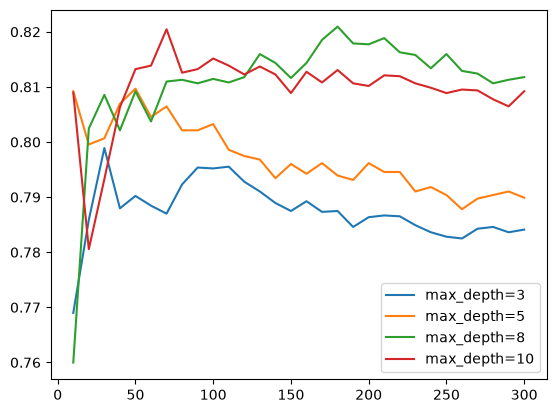

In [28]:
scores = []

for d in [3, 5, 8, 10]:
    for n in range(10, 301, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
        scores.append((d, n, auc))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'auc'])

for d in [3, 5, 8, 10]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)

plt.legend()
plt.show()

In [29]:
best_rf_depth = 8

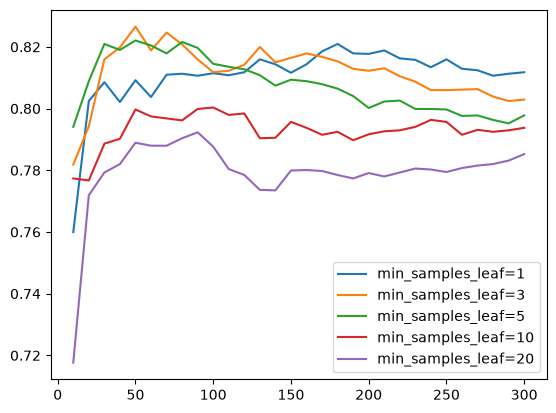

In [30]:
scores = []

for s in [1, 3, 5, 10, 20]:
    for n in range(10, 301, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=best_rf_depth, min_samples_leaf=s,
                                    random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
        scores.append((s, n, auc))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'auc'])

for s in [1, 3, 5, 10, 20]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='min_samples_leaf=%d' % s)

plt.legend()
plt.show()

In [31]:
best_rf_leaf = 5
best_rf_n = 150

### XGBoost

In [32]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
watchlist = [(dtrain, 'train'), (dval, 'val')]

def run_xgb(eta=0.3, max_depth=3, min_child_weight=1, rounds=200):
    params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'seed': 1,
        'verbosity': 0,
    }
    history = {}
    xgb.train(params, dtrain, num_boost_round=rounds, evals=watchlist,
              evals_result=history, verbose_eval=False)
    return history['val']['auc']

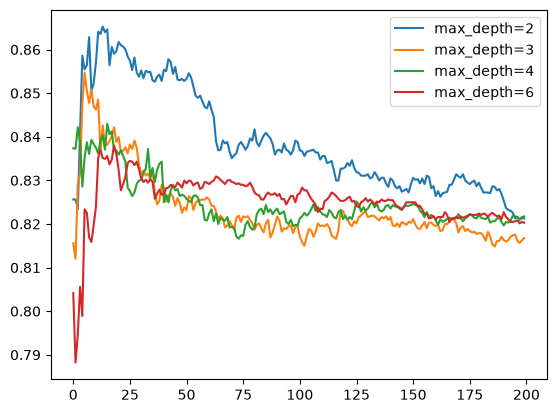

In [33]:
for max_depth in [2, 3, 4, 6]:
    plt.plot(run_xgb(max_depth=max_depth), label='max_depth=%s' % max_depth)

plt.legend()
plt.show()

In [34]:
best_xgb_depth = 2

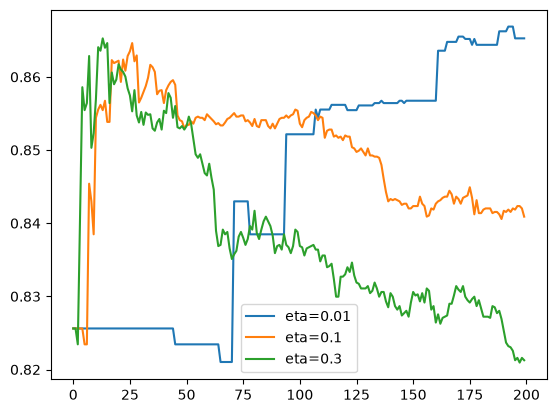

In [35]:
for eta in [0.01, 0.1, 0.3]:
    plt.plot(run_xgb(eta=eta, max_depth=best_xgb_depth), label='eta=%s' % eta)

plt.legend()
plt.show()

In [36]:
best_eta = 0.1

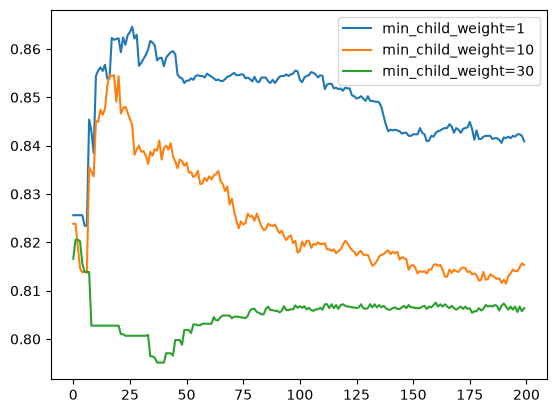

In [37]:
for mcw in [1, 10, 30]:
    plt.plot(run_xgb(eta=best_eta, max_depth=best_xgb_depth, min_child_weight=mcw),
             label='min_child_weight=%s' % mcw)

plt.legend()
plt.show()

In [38]:
best_mcw = 1

In [39]:
auc_curve = run_xgb(eta=best_eta, max_depth=best_xgb_depth, min_child_weight=best_mcw)
smooth = pd.Series(auc_curve).rolling(10, center=True).mean()
best_rounds = int(smooth.idxmax()) + 1
best_rounds, smooth.max()

(25, np.float64(0.8622828185328185))

### Comparison

In [40]:
def make_model(name):
    if name == 'logistic regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=1000))
    if name == 'decision tree':
        return DecisionTreeClassifier(max_depth=best_dt_depth, min_samples_leaf=best_dt_leaf, random_state=1)
    if name == 'random forest':
        return RandomForestClassifier(n_estimators=best_rf_n, max_depth=best_rf_depth,
                                      min_samples_leaf=best_rf_leaf, random_state=1, n_jobs=-1)

def val_auc(name, cols):
    dv_ = DictVectorizer(sparse=False)
    X_tr = dv_.fit_transform(df_train[cols].to_dict(orient='records'))
    X_va = dv_.transform(df_val[cols].to_dict(orient='records'))

    if name == 'xgboost':
        names = list(dv_.get_feature_names_out())
        d_tr = xgb.DMatrix(X_tr, label=y_train, feature_names=names)
        d_va = xgb.DMatrix(X_va, feature_names=names)
        params = {'eta': best_eta, 'max_depth': best_xgb_depth, 'min_child_weight': best_mcw,
                  'objective': 'binary:logistic', 'eval_metric': 'auc', 'seed': 1, 'verbosity': 0}
        model = xgb.train(params, d_tr, num_boost_round=best_rounds)
        return roc_auc_score(y_val, model.predict(d_va))

    model = make_model(name)
    model.fit(X_tr, y_train)
    return roc_auc_score(y_val, model.predict_proba(X_va)[:, 1])

In [41]:
set_A = audio + ['key', 'mode']
set_B = set_A + ['artist_count', 'released_month']
set_C = features

feature_sets = {'A: music only': set_A, 'B: + artist count, month': set_B, 'C: + release year': set_C}

rows = []
for set_name, cols in feature_sets.items():
    for name in ['logistic regression', 'decision tree', 'random forest', 'xgboost']:
        rows.append({'features': set_name, 'model': name, 'val_auc': val_auc(name, cols)})

results = pd.DataFrame(rows)
results.pivot(index='model', columns='features', values='val_auc').round(3)

features,A: music only,"B: + artist count, month",C: + release year
model,,,
decision tree,0.450,0.588,0.859
logistic regression,0.423,0.568,0.613
random forest,0.489,0.575,0.809
xgboost,0.479,0.584,0.863


### Final Model

In [42]:
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train['mega_hit'].values

full_train_dicts = df_full_train[features].to_dict(orient='records')
test_dicts = df_test[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(full_train_dicts)
X_test = dv.transform(test_dicts)

feature_names = list(dv.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=feature_names)
dtest = xgb.DMatrix(X_test, feature_names=feature_names)

xgb_params = {
    'eta': best_eta,
    'max_depth': best_xgb_depth,
    'min_child_weight': best_mcw,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 1,
    'verbosity': 0,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=best_rounds)

y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

0.890505138225503

## Evaluation

In [43]:
y_pred_test = y_pred

model_val = xgb.train(xgb_params, dtrain, num_boost_round=best_rounds)
y_pred_val = model_val.predict(dval)

roc_auc_score(y_val, y_pred_val)

0.8628539253539254

In [44]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred_test >= 0.5), round(1 - y_test.mean(), 3)

(0.8157894736842105, np.float64(0.742))

- Accuracy is 81.6%, but a dummy that always says "not a mega-hit" gets 74.2%, so we're only about 7 points better. Only ~25% of songs are mega-hits, so accuracy alone is misleading.

In [45]:
def threshold_table(y_true, y_score):
    rows = []
    for t in np.linspace(0, 1, 101):
        actual_positive = (y_true == 1)
        actual_negative = (y_true == 0)
        predict_positive = (y_score >= t)
        predict_negative = (y_score < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        rows.append((t, tp, fp, fn, tn))

    df_t = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])
    df_t['precision'] = df_t.tp / (df_t.tp + df_t.fp)
    df_t['recall'] = df_t.tp / (df_t.tp + df_t.fn)
    return df_t

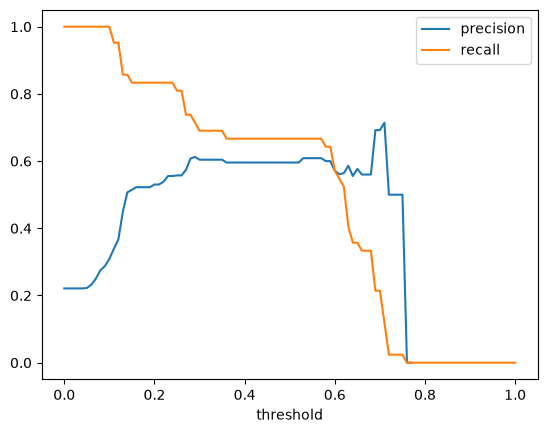

,threshold,tp,fp,fn,tn,precision,recall
0,0.00,42,148,0,0,0.22,1.00
5,0.05,42,147,0,1,0.22,1.00
10,0.10,42,94,0,54,0.31,1.00
15,0.15,35,33,7,115,0.51,0.83
20,0.20,35,31,7,117,0.53,0.83
25,0.25,34,27,8,121,0.56,0.81
30,0.30,29,19,13,129,0.60,0.69
35,0.35,29,19,13,129,0.60,0.69
40,0.40,28,19,14,129,0.60,0.67
45,0.45,28,19,14,129,0.60,0.67


In [46]:
df_val_scores = threshold_table(y_val, y_pred_val)

plt.plot(df_val_scores.threshold, df_val_scores.precision, label='precision')
plt.plot(df_val_scores.threshold, df_val_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

df_val_scores.iloc[::5].round(2)

- From a threshold of 0.3 to 0.55, precision stays around 0.6 and recall around 0.67.
- Lower thresholds catch more mega-hits but flag more wrong songs (at 0.15: recall 0.83, precision 0.51). Above 0.6, recall drops fast.

In [47]:
threshold = 0.35

In [48]:
actual_positive = (y_test == 1)
actual_negative = (y_test == 0)
predict_positive = (y_pred_test >= threshold)
predict_negative = (y_pred_test < threshold)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = np.array([[tn, fp], [fn, tp]])
confusion_matrix

array([[120,  21],
       [ 15,  34]])

In [49]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.63, 0.11],
       [0.08, 0.18]])

In [50]:
p = tp / (tp + fp)
r = tp / (tp + fn)
p, r

(np.float64(0.6181818181818182), np.float64(0.6938775510204082))

- Confusion table (test set, 190 songs, threshold 0.35)
- 120 true negatives, 21 false positives, 15 false negatives, 34 true positives.
- Precision 0.62: about 3 out of 5 songs flagged as mega-hits really are.
- Recall 0.69: we catch about 7 out of 10 real mega-hits and miss 15.
- I picked 0.35 from the validation table, where precision and recall are flat from 0.3 to 0.55, and favored catching more mega-hits. At 0.5 the test results are almost the same (precision 0.64, recall 0.65).

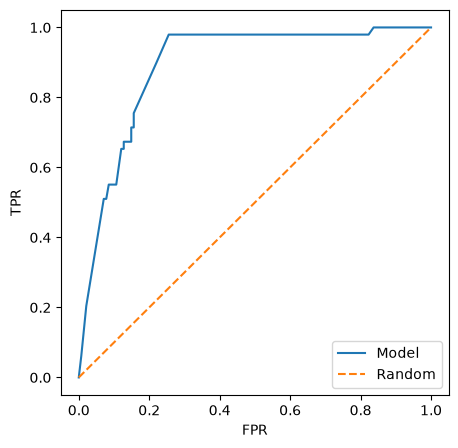

In [51]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.show()

- The curve is well above the random diagonal, and it reaches ~98% of mega-hits at ~25% false positives.
- It's blocky because the model is small (25 trees, depth 2), so it gives few distinct scores.

In [52]:
from sklearn.model_selection import KFold

def train_xgb(df, y):
    dicts = df[features].to_dict(orient='records')
    dv_ = DictVectorizer(sparse=False)
    X = dv_.fit_transform(dicts)
    d = xgb.DMatrix(X, label=y, feature_names=list(dv_.get_feature_names_out()))
    return dv_, xgb.train(xgb_params, d, num_boost_round=best_rounds)

def predict_xgb(df, dv_, model_):
    X = dv_.transform(df[features].to_dict(orient='records'))
    d = xgb.DMatrix(X, feature_names=list(dv_.get_feature_names_out()))
    return model_.predict(d)

In [53]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]
    y_tr = y_full_train[train_idx]
    y_va = y_full_train[val_idx]

    dv_, m = train_xgb(df_tr, y_tr)
    y_p = predict_xgb(df_va, dv_, m)

    scores.append(roc_auc_score(y_va, y_p))

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.868 +- 0.013


- 5-fold cross-validation AUC is 0.868 +- 0.013, close to validation (0.863) and test (0.890), so the model is stable and not overfitting.
- It's slightly optimistic because I tuned the parameters on part of this data.

In [54]:
importance = model.get_score(importance_type='gain')
pd.Series(importance).sort_values(ascending=False).head(10).round(1)

released_year        33.4
released_month=11     8.4
released_month=3      6.6
instrumentalness      4.6
speechiness           4.4
released_month=1      4.2
danceability          4.1
released_month=7      3.9
liveness              2.7
dtype: float64

- `released_year` is by far the biggest driver (gain 33 vs 8 or less for everything else).
- A few release months and audio features show up with small gains, but music-only models scored at chance, so I'm not reading much into them.
- Takeaway: whether a song is a mega-hit here is mostly about how long ago it was released.